# Retail Store Sales: Data Cleaning, Exploratory Data Analysis and Sales Trends Using Python

# INTRODUCTION AND OBJECTIVE

This project analyzes a retail store sales dataset using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn. The objective is to clean and understand the data, investigate sales patterns, compare product categories and payment methods, analyze transaction trends, and communicate useful findings through statistical analysis and visualizations.

# QUESTIONS
1. Which categories generate the highest recorded sales?

2. How do sales vary over time?

3. Which payment methods are most frequently used?

4. How do sales differ by location and discount status?

5. What data-quality issues need to be resolved before analysis? 

In [1]:
# Load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"retail_store_sales.csv")
df

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
...,...,...,...,...,...,...,...,...,...,...,...
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12571,TXN_4009414,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,False
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN
12573,TXN_5167298,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,True


In [2]:
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


# Understand the dataset

In [3]:
df.tail()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12571,TXN_4009414,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,False
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN
12573,TXN_5167298,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,True
12574,TXN_2407494,CUST_23,Food,Item_9_FOOD,17.0,3.0,51.0,Cash,Online,2022-08-06,NaN


In [4]:
#Shape
df.shape

(12575, 11)

In [5]:
#Columns
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')

In [6]:
# Structural overview
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.9+ MB


In [7]:
# Numeric summary
df.describe()

,Price Per Unit,Quantity,Total Spent
count,11966.000000,11971.000000,11971.000000
mean,23.365912,5.536380,129.652577
std,10.743519,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


In [8]:
df.dtypes

Transaction ID          str
Customer ID             str
Category                str
Item                    str
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method          str
Location                str
Transaction Date        str
Discount Applied     object
dtype: object

# Missing values

In [9]:
# missing values in each column
df.isnull().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [10]:
# percentage of missing values in each column
df.isnull().mean() * 100

Transaction ID       0.000000
Customer ID          0.000000
Category             0.000000
Item                 9.646123
Price Per Unit       4.842942
Quantity             4.803181
Total Spent          4.803181
Payment Method       0.000000
Location             0.000000
Transaction Date     0.000000
Discount Applied    33.391650
dtype: float64

In [11]:
# No.Duplicate rows
df.duplicated().sum()

np.int64(0)

In [12]:
# Duplicated rows
df[df.duplicated()]

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied


In [13]:
# Unique values
df.nunique()

Transaction ID      12575
Customer ID            25
Category                8
Item                  200
Price Per Unit         25
Quantity               10
Total Spent           227
Payment Method          3
Location                2
Transaction Date     1114
Discount Applied        2
dtype: int64

In [14]:
df["Category"].value_counts()

Category
Furniture                             1591
Electric household essentials         1591
Food                                  1588
Milk Products                         1584
Butchers                              1568
Beverages                             1567
Computers and electric accessories    1558
Patisserie                            1528
Name: count, dtype: int64

In [15]:
df["Payment Method"].value_counts()

Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

In [16]:
df["Location"].value_counts()

Location
Online      6354
In-store    6221
Name: count, dtype: int64

In [17]:
df["Discount Applied"].value_counts()

Discount Applied
True     4219
False    4157
Name: count, dtype: int64

# Clean data

In [18]:
df.columns = df.columns.str.replace(" ", "_")
df.columns

Index(['Transaction_ID', 'Customer_ID', 'Category', 'Item', 'Price_Per_Unit',
       'Quantity', 'Total_Spent', 'Payment_Method', 'Location',
       'Transaction_Date', 'Discount_Applied'],
      dtype='str')

In [19]:
#Turn the date column into real date
df["Transaction_Date"]=pd.to_datetime(df["Transaction_Date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    12575 non-null  str           
 1   Customer_ID       12575 non-null  str           
 2   Category          12575 non-null  str           
 3   Item              11362 non-null  str           
 4   Price_Per_Unit    11966 non-null  float64       
 5   Quantity          11971 non-null  float64       
 6   Total_Spent       11971 non-null  float64       
 7   Payment_Method    12575 non-null  str           
 8   Location          12575 non-null  str           
 9   Transaction_Date  12575 non-null  datetime64[us]
 10  Discount_Applied  8376 non-null   object        
dtypes: datetime64[us](1), float64(3), object(1), str(6)
memory usage: 1.8+ MB


In [20]:
df["Year"]=df["Transaction_Date"].dt.year
df["Year"]

0        2024
1        2023
2        2022
3        2022
4        2022
         ... 
12570    2023
12571    2022
12572    2024
12573    2023
12574    2022
Name: Year, Length: 12575, dtype: int32

In [21]:
df["Month"] = df["Transaction_Date"].dt.month
df["Month"]

0         4
1         7
2        10
3         5
4        10
         ..
12570     9
12571     8
12572     8
12573    12
12574     8
Name: Month, Length: 12575, dtype: int32

In [22]:
df.isnull().sum()

Transaction_ID         0
Customer_ID            0
Category               0
Item                1213
Price_Per_Unit       609
Quantity             604
Total_Spent          604
Payment_Method         0
Location               0
Transaction_Date       0
Discount_Applied    4199
Year                   0
Month                  0
dtype: int64

In [23]:
df.describe()

,Price_Per_Unit,Quantity,Total_Spent,Transaction_Date,Year,Month
count,11966.000000,11971.000000,11971.000000,12575,12575.000000,12575.000000
mean,23.365912,5.536380,129.652577,2023-07-12 20:23:41.105367,2023.042386,6.366441
min,5.000000,1.000000,5.000000,2022-01-01 00:00:00,2022.000000,1.000000
25%,14.000000,3.000000,51.000000,2022-09-30 00:00:00,2022.000000,3.000000
50%,23.000000,6.000000,108.500000,2023-07-13 00:00:00,2023.000000,6.000000
75%,33.500000,8.000000,192.000000,2024-04-24 00:00:00,2024.000000,9.000000
max,41.000000,10.000000,410.000000,2025-01-18 00:00:00,2025.000000,12.000000
std,10.743519,2.857883,94.750697,NaN,0.855581,3.503156


In [24]:
df["Item"]=df["Item"].fillna(df["Item"].mode()[0])


In [25]:
df["Item"]

0         Item_10_PAT
1        Item_17_MILK
2         Item_12_BUT
3         Item_16_BEV
4         Item_6_FOOD
             ...     
12570     Item_23_PAT
12571      Item_2_BEV
12572      Item_7_BUT
12573      Item_7_FUR
12574     Item_9_FOOD
Name: Item, Length: 12575, dtype: str

In [26]:
df["Price_Per_Unit"]=df["Price_Per_Unit"].fillna(df["Price_Per_Unit"].mean())

In [27]:
df["Price_Per_Unit"]

0        18.5
1        29.0
2        21.5
3        27.5
4        12.5
         ... 
12570    38.0
12571     6.5
12572    14.0
12573    14.0
12574    17.0
Name: Price_Per_Unit, Length: 12575, dtype: float64

In [28]:
df["Quantity"]=df["Quantity"].fillna(df["Quantity"].median())
df["Quantity"]=df["Quantity"].astype(int)

In [29]:
df["Quantity"]

0        10
1         9
2         2
3         9
4         7
         ..
12570     4
12571     9
12572    10
12573     6
12574     3
Name: Quantity, Length: 12575, dtype: int64

In [30]:
df["Total_Spent"]=df["Total_Spent"].fillna(df["Total_Spent"].median())

In [31]:
df["Total_Spent"]

0        185.0
1        261.0
2         43.0
3        247.5
4         87.5
         ...  
12570    152.0
12571     58.5
12572    140.0
12573     84.0
12574     51.0
Name: Total_Spent, Length: 12575, dtype: float64

In [32]:
df["Discount_Applied"]=df["Discount_Applied"].fillna(df["Discount_Applied"].mode()[0])

In [33]:
df["Discount_Applied"]

0         True
1         True
2        False
3         True
4        False
         ...  
12570     True
12571    False
12572     True
12573     True
12574     True
Name: Discount_Applied, Length: 12575, dtype: object

In [34]:
df.isnull().sum()

Transaction_ID      0
Customer_ID         0
Category            0
Item                0
Price_Per_Unit      0
Quantity            0
Total_Spent         0
Payment_Method      0
Location            0
Transaction_Date    0
Discount_Applied    0
Year                0
Month               0
dtype: int64

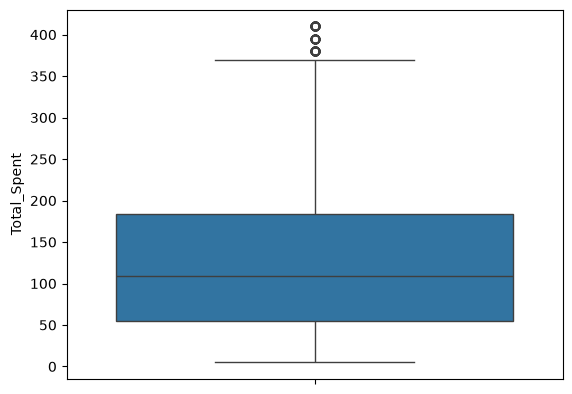

In [35]:
#Finding outliers and removing them
sns.boxplot(df["Total_Spent"])
plt.show()


In [36]:
Q1 = df["Total_Spent"].quantile(0.25)
Q3 = df["Total_Spent"].quantile(0.75)

IQR = Q3 - Q1

lowerbound = Q1 - 1.5 * IQR
upperbound = Q3 + 1.5 * IQR
outliers = df[(df["Total_Spent"] < lowerbound) | (df["Total_Spent"]> upperbound)]
outliers.shape

(157, 13)

In [40]:
#Examine the outliers
outliers[[
    "Transaction_ID",
    "Category",
    "Item",
    "Price_Per_Unit",
    "Quantity",
    "Total_Spent"
]].head(20)

,Transaction_ID,Category,Item,Price_Per_Unit,Quantity,Total_Spent
27,TXN_1599706,Furniture,Item_25_FUR,41.000000,10,410.0
120,TXN_8215469,Milk Products,Item_23_MILK,38.000000,10,380.0
129,TXN_1112365,Food,Item_24_FOOD,39.500000,10,395.0
133,TXN_2953434,Furniture,Item_25_FUR,41.000000,10,410.0
135,TXN_1249742,Milk Products,Item_24_MILK,39.500000,10,395.0
146,TXN_2565828,Food,Item_24_FOOD,39.500000,10,395.0
339,TXN_4374445,Food,Item_25_FOOD,41.000000,10,410.0
485,TXN_4412300,Electric household essentials,Item_23_EHE,38.000000,10,380.0
668,TXN_5476798,Butchers,Item_2_BEV,23.365912,10,380.0
869,TXN_1814138,Beverages,Item_25_BEV,41.000000,10,410.0


In [41]:
df=df[(df["Total_Spent"]>=lowerbound)&(df["Total_Spent"]<=upperbound)]


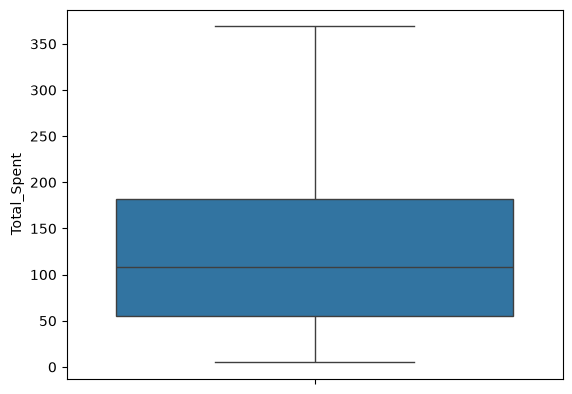

In [42]:
sns.boxplot(df["Total_Spent"])    # outliers removed
plt.show()

# GroupBy Analysis

In [43]:
category_sales=df.groupby("Category")["Total_Spent"].sum().sort_values(ascending =False) 
category_sales
# category butchers generate higest sales

Category
Butchers                              204140.0
Electric household essentials         203261.0
Computers and electric accessories    197491.0
Food                                  196325.5
Beverages                             195561.0
Furniture                             191426.0
Patisserie                            184615.0
Milk Products                         182740.5
Name: Total_Spent, dtype: float64

In [44]:
df.groupby("Category")["Total_Spent"].mean()

Category
Beverages                             126.658679
Butchers                              132.730819
Computers and electric accessories    127.167418
Electric household essentials         129.548120
Food                                  125.048089
Furniture                             122.473448
Milk Products                         116.321133
Patisserie                            122.261589
Name: Total_Spent, dtype: float64

In [45]:
df.groupby(["Location","Discount_Applied"])["Total_Spent"].sum().sort_values(ascending = False)

Location  Discount_Applied
Online    True                528565.5
In-store  True                510639.0
Online    False               263026.5
In-store  False               253329.0
Name: Total_Spent, dtype: float64

In [46]:
payment_counts=df.groupby("Payment_Method")["Transaction_ID"].count().sort_values(ascending =False)
payment_counts

Payment_Method
Cash              4263
Digital Wallet    4089
Credit Card       4066
Name: Transaction_ID, dtype: int64

In [47]:
df.groupby("Month")["Total_Spent"].sum().sort_values(ascending= False)

Month
1     174062.0
7     132589.0
12    130165.0
6     129370.5
9     127023.5
5     126172.0
4     125224.0
11    124177.0
8     123162.0
3     122706.0
2     120671.5
10    120237.5
Name: Total_Spent, dtype: float64

# Exploratory Data Analysis (EDA)

# 1.Univariate analysis — one variable

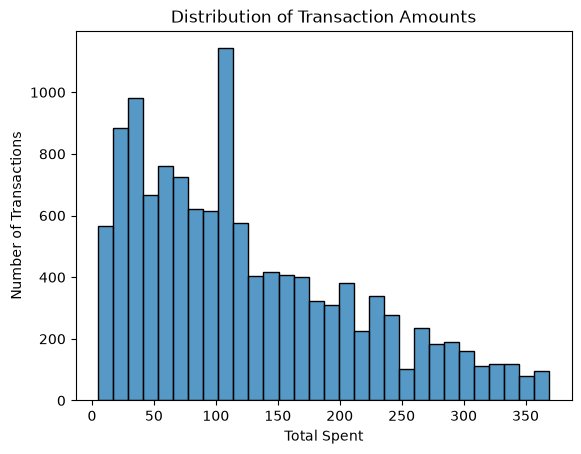

In [48]:
sns.histplot(data=df, x="Total_Spent", bins=30)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Total Spent")
plt.ylabel("Number of Transactions")
plt.show()

#Insight: 
Most transactions are concentrated within the lower-to-middle spending range.
The average transaction amount is approximately 129.65, while the median is 108.50.
The difference between the mean and median suggests that some higher-value transactions may be pulling the average upward.

YearMonth
2022-01    52548.5
2022-02    43303.5
2022-03    41725.0
2022-04    41364.0
2022-05    40775.0
2022-06    42020.5
2022-07    45248.5
2022-08    39894.5
2022-09    43707.0
2022-10    38309.0
2022-11    42102.5
2022-12    39053.0
2023-01    48061.0
2023-02    39657.0
2023-03    39218.0
2023-04    39363.0
2023-05    41001.5
2023-06    42729.5
2023-07    46159.0
2023-08    38037.0
2023-09    41023.0
2023-10    39129.5
2023-11    36781.0
2023-12    42179.0
2024-01    47895.5
2024-02    37711.0
2024-03    41763.0
2024-04    44497.0
2024-05    44395.5
2024-06    44620.5
2024-07    41181.5
2024-08    45230.5
2024-09    42293.5
2024-10    42799.0
2024-11    45293.5
2024-12    48933.0
2025-01    25557.0
Freq: M, Name: Total_Spent, dtype: float64


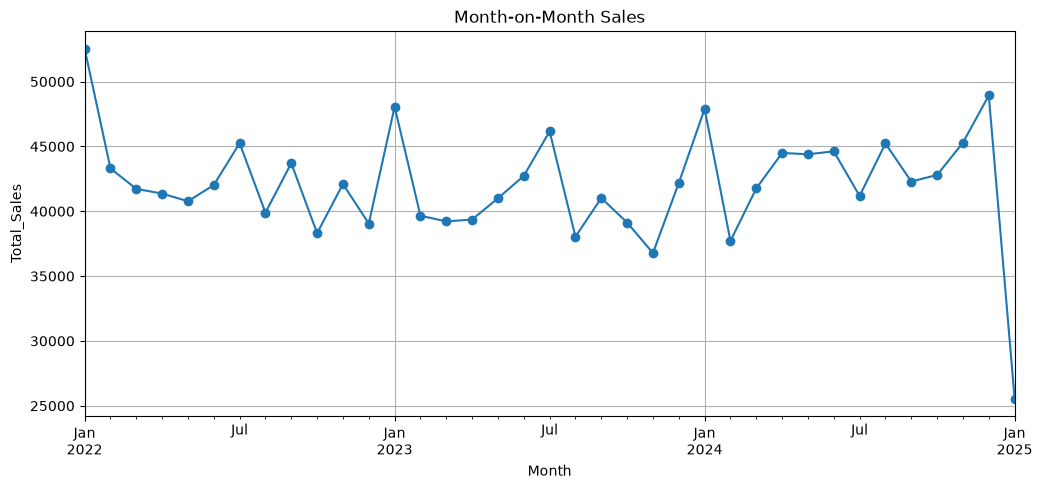

In [52]:
# Make a Year-Month column (needs Transaction Date to be a real date)
df["YearMonth"] = df["Transaction_Date"].dt.to_period("M")
monthly_sales = df.groupby("YearMonth")["Total_Spent"].sum()
print(monthly_sales)

monthly_sales.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Month-on-Month Sales")
plt.xlabel("Month")
plt.ylabel("Total_Sales")
plt.grid(True)
plt.show()

#Insight:
Monthly sales fluctuate throughout the observed period rather than following a consistent upward trend.
December 2024 recorded relatively high sales, approximately 48,933.
January 2025 recorded lower sales, approximately 25,557. However, the dataset ends on January 18, 2025, so this is an incomplete month.

Payment_Method
Cash              4263
Digital Wallet    4089
Credit Card       4066
Name: count, dtype: int64


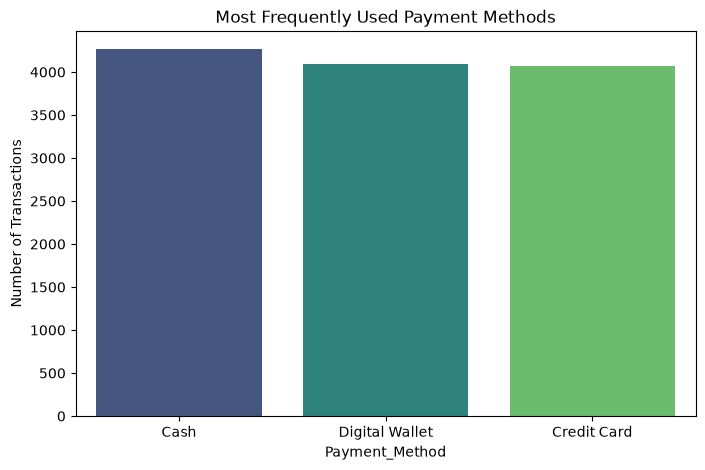

In [53]:
payment_counts = df["Payment_Method"].value_counts()
print(payment_counts)
plt.figure(figsize=(8, 5))

sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values,hue=payment_counts.index,palette="viridis",legend=False
)

plt.title("Most Frequently Used Payment Methods")
plt.xlabel("Payment_Method")
plt.ylabel("Number of Transactions")
plt.show()



#Insight:
Cash was the most frequently used payment method, with 4,263 transactions.
Digital Wallet recorded 4,089 transactions.
Credit Card recorded 4,066 transactions.
The differences between payment methods are relatively small.

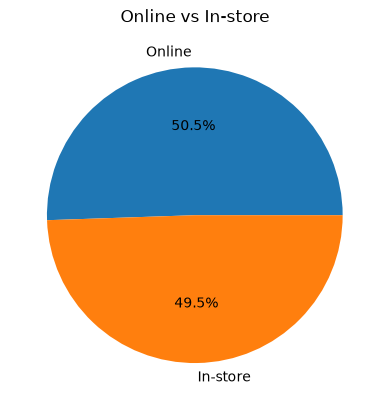

In [54]:
df["Location"].value_counts().plot(kind="pie", autopct ="%1.1f%%")
plt.title("Online vs In-store")
plt.show()

# Insight:
The distribution indicates a nearly balanced customer preference between online and physical shopping.

# Bivariate analysis — two variables

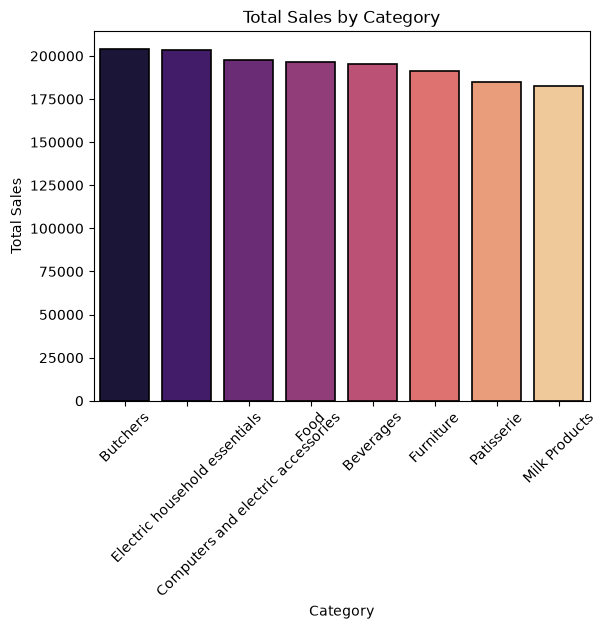

In [55]:
# Which category generated the highest recorded sales
sns.barplot(
    x=category_sales.index,y=category_sales.values, hue=category_sales.index,palette="magma",legend=False,
    edgecolor="black",
    linewidth=1.2)
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation =45)
plt.show()

#Insight:
Butchers generated the highest recorded sales, totaling 204,140.
Electric Household Essentials followed with 203,261.
Milk Products generated the lowest sales among the categories, totaling 182,740.50.
The differences between categories are relatively small

# Multivariate (many columns)

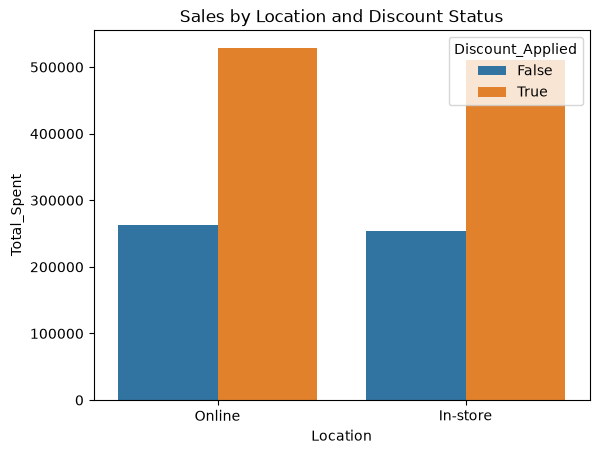

In [56]:
# How sales differ by location and discount status
sns.barplot(
    data=df,
    x="Location",
    y="Total_Spent",
    hue="Discount_Applied",
    estimator="sum",
    errorbar=None
)

plt.title("Sales by Location and Discount Status")
plt.show()

#Insight:
Online transactions with discounts recorded the highest sales, totaling 528,565.50.
In-store transactions with discounts recorded 510,639.
Transactions without discounts generated lower total sales in both locations.
Discount-applied transactions account for a larger share of recorded sales.

In [58]:
# top 5 sales
df.sort_values("Total_Spent", ascending=False).head(5)   

,Transaction_ID,Customer_ID,Category,Item,Price_Per_Unit,Quantity,Total_Spent,Payment_Method,Location,Transaction_Date,Discount_Applied,Year,Month,YearMonth
3642,TXN_6016967,CUST_07,Furniture,Item_25_FUR,41.0,9,369.0,Cash,Online,2022-08-15,True,2022,8,2022-08
973,TXN_9981851,CUST_03,Furniture,Item_25_FUR,41.0,9,369.0,Digital Wallet,Online,2024-11-27,True,2024,11,2024-11
10160,TXN_5044628,CUST_01,Butchers,Item_25_BUT,41.0,9,369.0,Digital Wallet,In-store,2022-01-07,True,2022,1,2022-01
5382,TXN_3155102,CUST_17,Computers and electric accessories,Item_25_CEA,41.0,9,369.0,Digital Wallet,In-store,2024-03-19,False,2024,3,2024-03
10117,TXN_4189375,CUST_24,Food,Item_25_FOOD,41.0,9,369.0,Cash,In-store,2024-05-31,True,2024,5,2024-05


In [60]:
# botton 5 sales
df.sort_values("Total_Spent").head(5) 

,Transaction_ID,Customer_ID,Category,Item,Price_Per_Unit,Quantity,Total_Spent,Payment_Method,Location,Transaction_Date,Discount_Applied,Year,Month,YearMonth
12470,TXN_7765690,CUST_25,Patisserie,Item_1_PAT,5.0,1,5.0,Cash,Online,2024-03-03,True,2024,3,2024-03
2715,TXN_3217988,CUST_25,Milk Products,Item_1_MILK,5.0,1,5.0,Digital Wallet,Online,2023-04-05,True,2023,4,2023-04
4727,TXN_2006169,CUST_23,Beverages,Item_1_BEV,5.0,1,5.0,Digital Wallet,Online,2024-09-09,True,2024,9,2024-09
5063,TXN_8786976,CUST_01,Milk Products,Item_1_MILK,5.0,1,5.0,Credit Card,Online,2022-04-12,True,2022,4,2022-04
9468,TXN_6115982,CUST_25,Patisserie,Item_1_PAT,5.0,1,5.0,Cash,Online,2023-05-14,True,2023,5,2023-05


In [62]:
pd.pivot_table(df, values="Total_Spent", index="Category", columns="Location", aggfunc="sum")
pd.crosstab(df["Payment_Method"], df["Location"])

Location,In-store,Online
Payment_Method,,
Cash,2116,2147
Credit Card,1992,2074
Digital Wallet,2034,2055


# Conclusion

This project involved cleaning and analyzing retail sales data using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn. The analysis identified sales trends, category performance, payment preferences, and discount patterns.

Butchers recorded the highest sales, while Milk Products recorded the lowest. Online and in-store sales were nearly balanced, and cash was the most frequently used payment method. Discount-applied transactions recorded higher sales, although their impact on profitability requires further investigation.

Overall, this project demonstrated the importance of data cleaning and exploratory data analysis in identifying business insights and supporting data-driven decisions. Further analysis of profitability, customer behavior, and sales forecasting could provide additional financial insights.